### 01_long_format.R

In [8]:
# 과제 1. 넓은 형식을 긴 형식으로
# 과제 1~8은 01 → 08 순서로 같은 R 세션에서 실행한다(앞 파일이 만든 객체를 이어서 쓴다).

library(tidyverse)
library(showtext)   # 그림의 한글 글꼴: 03 이후 모든 그림이 쓰므로 여기서 한 번 등록한다
font_add_google("Noto Sans KR", "noto")
showtext_auto()
showtext_opts(dpi = 150)
# 모든 그림 공통 스타일: 흰 배경, 연한 가로 격자만, 굵은 왼쪽 제목, 회색 축 글자, 하단 작은 * 설명
theme_set(theme_minimal(base_size = 12, base_family = "noto") +
  theme(panel.grid.major.x = element_blank(),
        panel.grid.minor = element_blank(),
        panel.grid.major.y = element_line(colour = "#E6E6E6", linewidth = 0.4),
        axis.text = element_text(colour = "#6E6E6E"),
        axis.title = element_blank(),   # 축 제목 대신 눈금에 단위를 붙인다
        plot.title = element_text(face = "bold", size = 15, margin = margin(b = 12)),
        plot.title.position = "plot",
        plot.caption = element_text(colour = "#8C8C8C", size = 8.5, hjust = 0, margin = margin(t = 10)),
        plot.caption.position = "plot",
        legend.position = "top", legend.justification = "left",
        legend.title = element_blank(), legend.text = element_text(colour = "#4D4D4D"),
        plot.margin = margin(16, 16, 12, 16)))
accent <- "#10A37F"   # 강조 색
muted <- "#C8C8C8"    # 비교 대상 색
hour_axis <- scale_x_continuous(breaks = 5:24, labels = c("~6", 6:23, "24~"))   # 시간대 x축(5 = 06시이전, 24 = 24시이후)

# 작업 폴더를 midterm_exam으로 맞춘다(code 폴더·midterm_exam·상위 ReadTheWorld 어디서 실행해도 같다, PC 경로를 적지 않음)
if (basename(getwd()) == "code") setwd("..")
if (dir.exists("midterm_exam")) setwd("midterm_exam")

subway <- read_csv("../dataset/working/subway_clean.csv")
nrow(subway)        # 바꾸기 전: 199,290

subway_long <- subway %>%
  pivot_longer(`06시이전`:`24시이후`, names_to = "시간대", values_to = "인원")
nrow(subway_long)   # 바꾼 뒤: 3,985,800

# 확인 1: 시간대 열이 20개이므로 20배여야 한다
nrow(subway_long) / nrow(subway)

# 확인 2: 바꾸기 전후 인원 총합이 같아야 한다
sum(select(subway, `06시이전`:`24시이후`)) == sum(subway_long$인원)

Rows: 199290 Columns: 25
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (3): 호선, 역, 구분
dbl  (21): 역번호, 06시이전, 06-07시간대, 07-08시간대, 08-09시간대, 09-10시간대, 10-11시간대, 11-...
date  (1): 날짜

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 199290

[1] 3985800

[1] 20

[1] TRUE

### 02_datetime.R

In [9]:
# 과제 2. 시간대에서 시각을 꺼내 날짜시각형으로
# 필요: 01_long_format.R 의 subway_long

# 06시이전은 첫차가 다니는 05시대이므로 5, 24시이후는 자정 넘은 막차이므로 24로 두어 시간 순서를 지킨다.
subway_long <- subway_long %>%
  mutate(시 = as.integer(str_extract(시간대, "^\\d+")),
         시 = if_else(시간대 == "06시이전", 5L, 시),
         일시 = as_datetime(날짜) + hours(시))
nrow(subway_long)   # 그대로 3,985,800

distinct(subway_long, 시간대, 시) %>% print(n = 20)   # 20개 시간대 → 시 대응
sum(is.na(subway_long$일시))                         # 0이어야 한다
filter(subway_long, 시간대 %in% c("06시이전", "24시이후")) %>% select(날짜, 시간대, 일시) %>% head(2)

[1] 3985800

# A tibble: 20 × 2
   시간대         시
   <chr>       <int>
 1 06시이전        5
 2 06-07시간대     6
 3 07-08시간대     7
 4 08-09시간대     8
 5 09-10시간대     9
 6 10-11시간대    10
 7 11-12시간대    11
 8 12-13시간대    12
 9 13-14시간대    13
10 14-15시간대    14
11 15-16시간대    15
12 16-17시간대    16
13 17-18시간대    17
14 18-19시간대    18
15 19-20시간대    19
16 20-21시간대    20
17 21-22시간대    21
18 22-23시간대    22
19 23-24시간대    23
20 24시이후       24


[1] 0

날짜,시간대,일시
<date>,<chr>,<dttm>
2025-01-01,06시이전,2025-01-01 05:00:00
2025-01-01,24시이후,2025-01-02 00:00:00


### 03_weekday_profile.R

[1] 7300

# A tibble: 20 × 4
   요일구분    시 평균승차   비율
   <chr>    <int>    <dbl>  <dbl>
 1 평일         5   64912.  1.32 
 2 평일         6  141930.  2.90 
 3 평일         7  383397.  7.82 
 4 평일         8  462151.  9.43 
 5 평일         9  270488.  5.52 
 6 평일        10  190227.  3.88 
 7 평일        11  188764.  3.85 
 8 평일        12  205290.  4.19 
 9 평일        13  212960.  4.34 
10 평일        14  222568.  4.54 
11 평일        15  259706.  5.30 
12 평일        16  315763.  6.44 
13 평일        17  452576.  9.23 
14 평일        18  569050. 11.6  
15 평일        19  287195.  5.86 
16 평일        20  223002.  4.55 
17 평일        21  207463.  4.23 
18 평일        22  160337.  3.27 
19 평일        23   69935.  1.43 
20 평일        24   14698.  0.300


요일구분,시,평균승차,비율
<chr>,<int>,<dbl>,<dbl>
주말,16,276014.0,8.419275
주말,17,261415.5,7.973976
주말,15,256279.4,7.817310


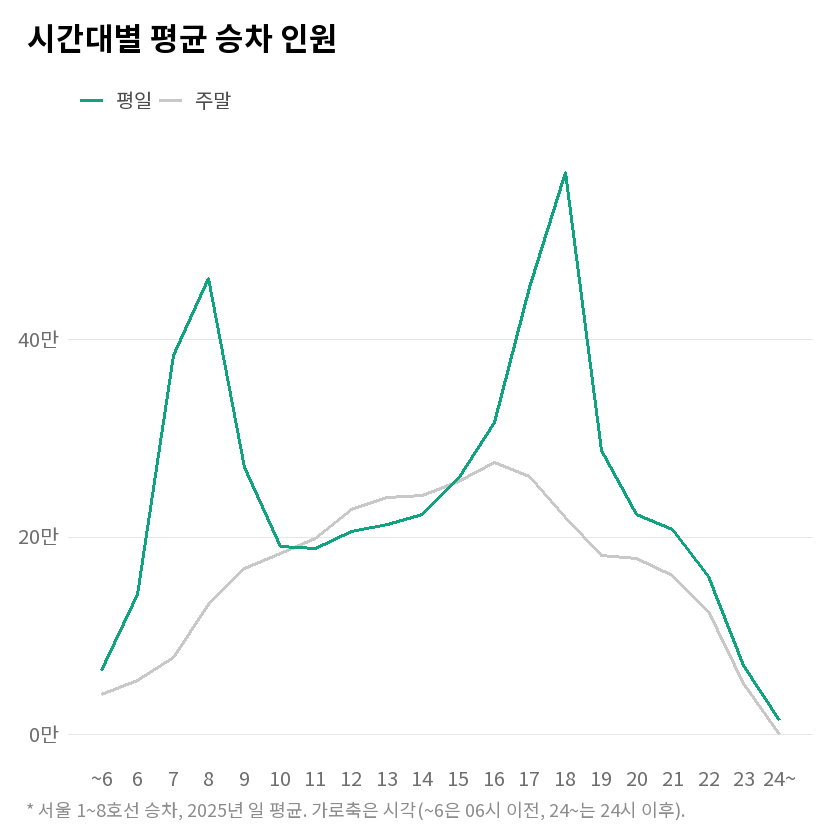

In [10]:
# 과제 3. 평일의 하루는 어떤 모양인가
# 필요: 02_datetime.R 의 subway_long(시 열)

# 승차만 골라 날짜 × 시별로 전 역을 더한다(서울 전체). 요일만으로 평일/주말을 나눈다(공휴일은 과제 6).
hourly <- subway_long %>%
  filter(구분 == "승차") %>%
  group_by(날짜, 시) %>%
  summarise(승차 = sum(인원), .groups = "drop") %>%
  mutate(요일구분 = if_else(wday(날짜) %in% c(1, 7), "주말", "평일"))
nrow(hourly)   # 365일 × 20 = 7,300

profile <- hourly %>%
  group_by(요일구분, 시) %>%
  summarise(평균승차 = mean(승차), .groups = "drop_last") %>%
  mutate(비율 = 평균승차 / sum(평균승차) * 100) %>%   # 하루 합 대비 %
  ungroup()
filter(profile, 요일구분 == "평일") %>% print(n = 20)
filter(profile, 요일구분 == "주말") %>% slice_max(평균승차, n = 3)   # 주말 상위 3개 시

# 결과(평일): 봉우리는 둘이다. 08시(08-09시간대) 46.2만 명으로 하루의 9.4%, 18시(18-19시간대) 56.9만 명으로 11.6%.
#   출근 07~08시와 퇴근 17~18시 네 시간대만 더해도 하루의 38.1%다.
# 결과(주말): 출퇴근 봉우리가 없고 16시(8.4%)를 꼭대기로 낮 내내 완만하다. 11~14시는 오히려 주말이 평일보다 많다.

dir.create("output/figures", recursive = TRUE, showWarnings = FALSE)

ggplot(profile, aes(x = 시, y = 평균승차 / 1e4, colour = 요일구분)) +
  geom_line(linewidth = 1.1) +
  hour_axis +
  scale_y_continuous(labels = ~ paste0(.x, "만")) +
  scale_colour_manual(values = c(평일 = accent, 주말 = muted), breaks = c("평일", "주말")) +
  labs(title = "시간대별 평균 승차 인원",
       x = NULL, y = NULL,
       caption = "* 서울 1~8호선 승차, 2025년 일 평균. 가로축은 시각(~6은 06시 이전, 24~는 24시 이후).")
ggsave("output/figures/03_hourly_profile.png", width = 9, height = 4.5, dpi = 150)

### 04_rain_by_hour.R

Rows: 365 Columns: 6
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): 지점명
dbl  (4): 지점, 평균기온(°C), 최고기온(°C), 일강수량(mm)
date (1): 일시

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 365

[1] 3985800

[1] 3985800

[1] 0

비,일수,n
<lgl>,<int>,<int>
FALSE,185,20
TRUE,76,20


# A tibble: 20 × 4
      시 비_FALSE 비_TRUE 차이율
   <int>    <dbl>   <dbl>  <dbl>
 1     5   65982.  62308.  -5.57
 2     6  143922. 137080.  -4.75
 3     7  389500. 368540.  -5.38
 4     8  469388. 444534.  -5.30
 5     9  274889. 259778.  -5.50
 6    10  193269. 182823.  -5.41
 7    11  191551. 181981.  -5.00
 8    12  208413. 197689.  -5.15
 9    13  216275. 204893.  -5.26
10    14  226160. 213824.  -5.45
11    15  263990. 249279.  -5.57
12    16  321179. 302578.  -5.79
13    17  460001. 434502.  -5.54
14    18  577442. 548622.  -4.99
15    19  291723. 276171.  -5.33
16    20  226842. 213653.  -5.81
17    21  211298. 198128.  -6.23
18    22  163144. 153503.  -5.91
19    23   71168.  66934.  -5.95
20    24   15061.  13813.  -8.29


시,비_FALSE,비_TRUE,차이율
<int>,<dbl>,<dbl>,<dbl>
24,15061.43,13812.58,-8.291698
21,211298.27,198127.67,-6.233179
23,71168.02,66933.64,-5.949831


시,비_FALSE,비_TRUE,차이율
<int>,<dbl>,<dbl>,<dbl>
6,143922.0,137080.2,-4.753816
18,577442.2,548622.4,-4.990941
11,191551.0,181981.1,-4.995968


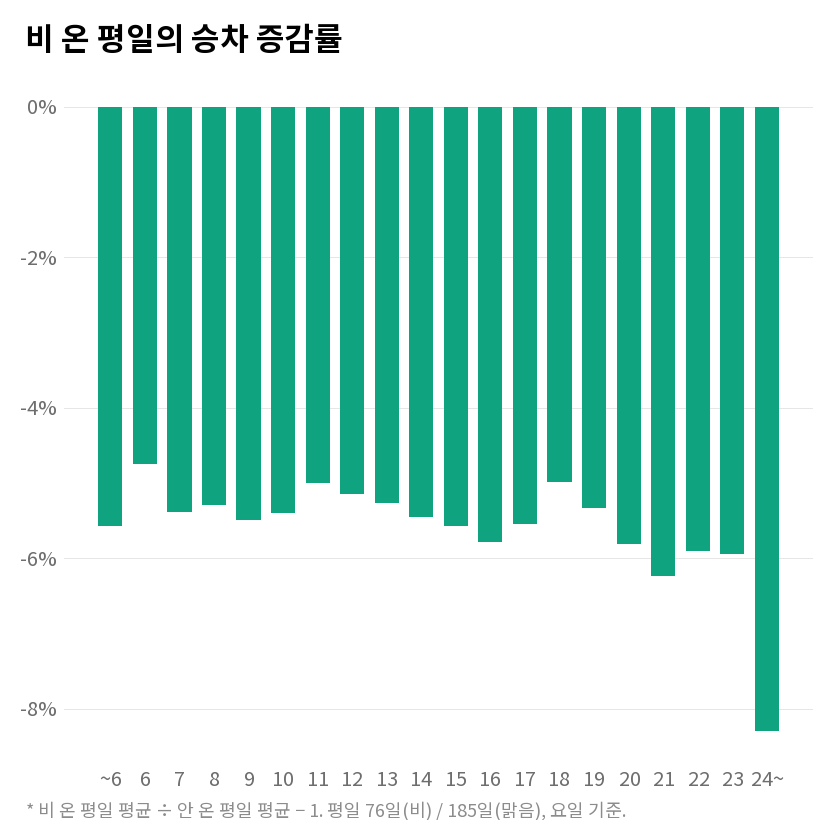

In [11]:
# 과제 4. 비 온 평일과 안 온 평일을 시간대별로 비교하기
# 필요: 02_datetime.R 의 subway_long(시 열)

# 기상 자료: 빈 강수량은 비가 오지 않은 날로 보고 0으로 채운다(4장 4.5)
weather <- read_csv("../dataset/raw/seoul-temp-raining-2025.csv",
                    locale = locale(encoding = "EUC-KR")) %>%
  transmute(날짜 = as_date(일시),
            강수량 = replace_na(`일강수량(mm)`, 0),
            비 = 강수량 > 0)
nrow(weather)   # 365

nrow(subway_long)                                   # 조인 전: 3,985,800
subway_long <- left_join(subway_long, weather, by = "날짜")
nrow(subway_long)                                   # 조인 후: 그대로여야 한다
sum(is.na(subway_long$비))                          # 못 붙은 행: 0이어야 한다

# 평일 승차만, 날짜 × 시별 서울 전체 합 → 비 × 시별 평균
rain_hourly <- subway_long %>%
  filter(구분 == "승차", !wday(날짜) %in% c(1, 7)) %>%
  group_by(날짜, 시, 비) %>%
  summarise(승차 = sum(인원), .groups = "drop") %>%
  group_by(시, 비) %>%
  summarise(일수 = n(), 평균승차 = mean(승차), .groups = "drop")
count(rain_hourly, 비, 일수)   # 평일 중 비 온 날 / 안 온 날 일수

rain_effect <- rain_hourly %>%
  select(-일수) %>%
  pivot_wider(names_from = 비, values_from = 평균승차, names_prefix = "비_") %>%
  mutate(차이율 = (비_TRUE / 비_FALSE - 1) * 100)
print(rain_effect, n = 20)

slice_min(rain_effect, 차이율, n = 3)   # 감소율이 가장 큰 시간대
slice_max(rain_effect, 차이율, n = 3)   # 감소율이 가장 작은 시간대

# 결과: 평일 비 온 날 76일, 안 온 날 185일. 모든 시간대에서 4.7~8.3% 줄었다.
#   감소율이 가장 큰 시간대: 24시이후(-8.3%), 21시(-6.2%), 23시(-6.0%) — 늦은 밤.
#   감소율이 가장 작은 시간대: 06시(-4.7%), 18시(-5.0%), 11시(-5.0%).
#   낮(09~15시)은 -5.0~-5.6%로 출퇴근 시간대(-5.0~-5.5%)와 거의 같다.

ggplot(rain_effect, aes(x = 시, y = 차이율)) +
  geom_col(fill = accent, width = 0.7) +
  hour_axis +
  scale_y_continuous(labels = ~ paste0(.x, "%")) +
  labs(title = "비 온 평일의 승차 증감률",
       x = NULL, y = NULL,
       caption = "* 비 온 평일 평균 ÷ 안 온 평일 평균 − 1. 평일 76일(비) / 185일(맑음), 요일 기준.")
ggsave("output/figures/04_rain_effect.png", width = 9, height = 4.5, dpi = 150)

### 05_daytime_judgement.R

In [12]:
# 과제 5. 판단하기: 낮 시간대를 봐야 하는가
# 필요: 03_weekday_profile.R 의 profile, 04_rain_by_hour.R 의 subway_long(비 열)·rain_hourly

# ① 시간대 묶음별 비 온 날 차이율(평일)
band_of <- function(h) case_when(h <= 6 ~ "1 새벽(05~06시)", h <= 8 ~ "2 출근(07~08시)",
                                 h <= 15 ~ "3 낮(09~15시)", h == 16 ~ "4 오후(16시)",
                                 h <= 18 ~ "5 퇴근(17~18시)", h <= 21 ~ "6 저녁(19~21시)",
                                 TRUE ~ "7 늦은 밤(22시~)")
rain_hourly %>%
  group_by(묶음 = band_of(시), 비) %>%
  summarise(승차 = sum(평균승차), .groups = "drop_last") %>%
  summarise(차이율 = (승차[비] / 승차[!비] - 1) * 100)

# ② 하루 합계에서 각 묶음이 차지하는 비율(평일, 과제 3)
profile %>%
  filter(요일구분 == "평일") %>%
  group_by(묶음 = band_of(시)) %>%
  summarise(비율 = sum(비율))

# ④ 6장 세 번째 시도(평일 비 온 날 ÷ 안 온 날 − 1)를 범위별로 다시 계산
weekday_daily <- subway_long %>%
  filter(구분 == "승차", !wday(날짜) %in% c(1, 7)) %>%
  group_by(날짜, 비) %>%
  summarise(하루 = sum(인원),
            일과_09_15 = sum(인원[시 %in% 9:15]),
            일과_10_14 = sum(인원[시 %in% 10:14]),
            .groups = "drop")
nrow(weekday_daily)   # 평일 261일

weekday_daily %>%
  group_by(비) %>%
  summarise(across(c(하루, 일과_09_15, 일과_10_14), mean)) %>%
  summarise(across(c(하루, 일과_09_15, 일과_10_14), ~ (.x[비] / .x[!비] - 1) * 100))

# ==== 판단(한 쪽 이내) ====
# 결론: 그림과 숫자는 "날씨의 영향은 일과시간(09~15시)에서 봐야 한다"는 주장을 뒷받침하지 않는다.
#   비 온 평일의 감소율은 낮(-5.4%)이 출퇴근(-5.3%, -5.2%)이나 하루 전체(-5.4%)와 거의 같고,
#   일과시간만 다시 계산해도 차이가 커지지 않았다(-5.3%). 가장 크게 준 때는 늦은 밤이었다.
#
# ① 시간대별 변화와 타는 이유
#   새벽(05~06시) -5.0%, 출근(07~08시) -5.3%, 퇴근(17~18시) -5.2%, 늦은 밤(22시~) -6.1%, 낮(09~15시) -5.4%.
#   새벽과 출퇴근은 출근·등교·업무처럼 날씨와 상관없이 해야 하는 이동이 대부분이라 줄어든 폭이 작다.
#   늦은 밤은 모임·여가 뒤 귀가처럼 미루거나 취소할 수 있는 이동이 섞여 있어 가장 많이 줄었다(24시이후 -8.3%).
#   낮에도 선택적 외출(쇼핑·병원·약속)이 있지만 업무 이동이 함께 섞여 있어 출퇴근과 비슷하게 줄었다.
#
# ② 출퇴근 비율과 희석
#   출근(07~08시) 17.2% + 퇴근(17~18시) 20.8% = 하루 합계의 약 38%. 낮(09~15시)은 31.6%다.
#   출퇴근 비중이 크면, 낮 시간대만 크게 줄어도 하루 합계에서는 그 변화가 약 3분의 1 크기로 묽어져 보인다.
#   이 희석 논리 자체는 맞지만, 실제로는 낮이 출퇴근보다 더 줄지 않았으므로 희석될 "숨은 큰 변화"가 없었다.
#
# ③ 09~15시 경계
#   과제 3 그림에서 09시(27.0만 명)는 아직 출근 봉우리의 꼬리이고 15시(26.0만 명)는 퇴근 오르막이 시작되는 때다.
#   평평한 낮 구간은 10시~15시 전(10~14시, 18.9만~22.3만 명)이다. 경계를 다시 잡는다면 10~14시다.
#
# ④ 6장 세 번째 시도(평일 차이 비율) 다시 계산
#   하루 전체 -5.43%, 일과시간 09~15시 -5.35%, 10~14시 -5.26%.
#   일과시간만 보면 감소율이 오히려 조금 작아진다. 범위를 바꿔도 결론이 같다.
#
# 단, 평일에는 아직 공휴일이 섞여 있고(과제 6), 비 온 날이 계절마다 고르지 않다(과제 7). 차이가 0.1~0.2%p 수준이라 판단은 "차이가 없다"에 가깝게 읽는다.

묶음,차이율
<chr>,<dbl>
1 새벽(05~06시),-5.009952
2 출근(07~08시),-5.334077
3 낮(09~15시),-5.352738
4 오후(16시),-5.791458
5 퇴근(17~18시),-5.235816
6 저녁(19~21시),-5.742372
7 늦은 밤(22시~),-6.064936


묶음,비율
<chr>,<dbl>
1 새벽(05~06시),4.219189
2 출근(07~08시),17.247589
3 낮(09~15시),31.617181
4 오후(16시),6.440963
5 퇴근(17~18시),20.839259
6 저녁(19~21시),14.638904
7 늦은 밤(22시~),4.996915


[1] 261

하루,일과_09_15,일과_10_14
<dbl>,<dbl>,<dbl>
-5.431757,-5.352738,-5.258327


### 06_holidays.R

Rows: 47 Columns: 3
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): 연도별 순번
dbl  (1): 연도
date (1): 공휴일

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 17

[1] 365

[1] 17

[1] 17

날짜,강수량,비,주말,휴일,쉬는날
<date>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>
2025-01-27,5.6,TRUE,FALSE,TRUE,TRUE
2025-01-28,0.1,TRUE,FALSE,TRUE,TRUE
2025-01-29,0.2,TRUE,FALSE,TRUE,TRUE
2025-03-03,10.4,TRUE,FALSE,TRUE,TRUE
2025-10-03,0.8,TRUE,FALSE,TRUE,TRUE
2025-10-06,36.8,TRUE,FALSE,TRUE,TRUE
2025-10-07,7.1,TRUE,FALSE,TRUE,TRUE


... (2 outputs left out)

[1] 0

기준,비,n,일수
<chr>,<lgl>,<int>,<dbl>
쉬는날,FALSE,3500,175
쉬는날,TRUE,1380,69
요일,FALSE,3700,185
요일,TRUE,1520,76


기준,하루,일과_09_15,일과_10_14,출퇴근
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
쉬는날,-2.607612,-3.118485,-3.211094,-1.992802
요일,-5.431757,-5.352738,-5.258327,-5.280321


# A tibble: 20 × 4
      시 쉬는날  요일  변화
   <int>  <dbl> <dbl> <dbl>
 1     5  -2.69 -5.57  2.88
 2     6  -1.60 -4.75  3.15
 3     7  -1.90 -5.38  3.48
 4     8  -1.81 -5.30  3.49
 5     9  -2.45 -5.50  3.05
 6    10  -3.05 -5.41  2.36
 7    11  -3.09 -5.00  1.91
 8    12  -3.10 -5.15  2.04
 9    13  -3.27 -5.26  2.00
10    14  -3.51 -5.45  1.95
11    15  -3.47 -5.57  2.10
12    16  -3.41 -5.79  2.39
13    17  -2.62 -5.54  2.92
14    18  -1.71 -4.99  3.28
15    19  -2.36 -5.33  2.97
16    20  -2.91 -5.81  2.90
17    21  -3.28 -6.23  2.96
18    22  -3.03 -5.91  2.88
19    23  -3.11 -5.95  2.83
20    24  -4.76 -8.29  3.53


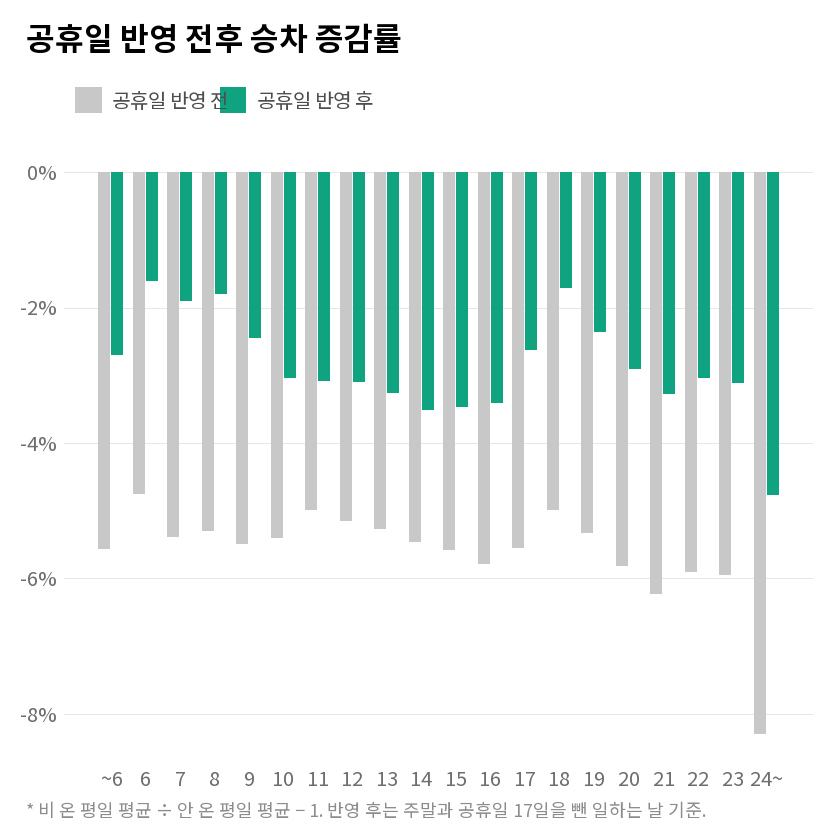

In [13]:
# 과제 6. 공휴일을 반영하면 달라지는가
# 필요: 03_weekday_profile.R 의 hourly(날짜 × 시 승차), 04_rain_by_hour.R 의 weather

# 출처: 공공데이터포털 공휴일 자료(data/OPENDATA_KOR_holidays_2025.csv, EUC-KR). 주말에 겹친 공휴일은 빠져 있다.
holidays <- read_csv("data/OPENDATA_KOR_holidays_2025.csv", locale = locale(encoding = "EUC-KR")) %>%
  filter(연도 == 2025) %>%
  pull(공휴일)
length(holidays)   # 17

day_type <- weather %>%
  mutate(주말 = wday(날짜) %in% c(1, 7),
         휴일 = 날짜 %in% holidays,   # 날짜형끼리 비교
         쉬는날 = 주말 | 휴일)
nrow(day_type)                         # 365
sum(day_type$휴일)                     # 휴일이 참인 날: 17
sum(day_type$휴일 & !day_type$주말)    # 그중 원래 평일로 분류된 날: 17(주말 공휴일은 목록에 없음)
filter(day_type, 휴일, 비)             # 공휴일에 비가 온 날

# 요일 기준(주말만 뺀 평일)과 쉬는날 기준(주말·공휴일을 뺀 일하는 날)을 나란히 계산
nrow(hourly)                                        # 7,300
hourly_day <- left_join(hourly, day_type, by = "날짜")
nrow(hourly_day)                                    # 그대로 7,300
sum(is.na(hourly_day$비))                           # 0

both <- bind_rows(요일 = filter(hourly_day, !주말),
                  쉬는날 = filter(hourly_day, !쉬는날),
                  .id = "기준")
count(both, 기준, 비) %>% mutate(일수 = n / 20)     # 기준별 비 온 날 / 안 온 날 일수

# (1) 6장 세 번째 시도 + 과제 5의 범위별 차이율
both %>%
  group_by(기준, 날짜, 비) %>%
  summarise(하루 = sum(승차),
            일과_09_15 = sum(승차[시 %in% 9:15]),
            일과_10_14 = sum(승차[시 %in% 10:14]),
            출퇴근 = sum(승차[시 %in% c(7, 8, 17, 18)]),
            .groups = "drop") %>%
  group_by(기준, 비) %>%
  summarise(across(하루:출퇴근, mean), .groups = "drop_last") %>%
  summarise(across(하루:출퇴근, ~ (.x[비] / .x[!비] - 1) * 100))

# (2) 과제 4의 시간대별 감소율 비교표
rain_compare <- both %>%
  group_by(기준, 시, 비) %>%
  summarise(평균승차 = mean(승차), .groups = "drop_last") %>%
  summarise(차이율 = (평균승차[비] / 평균승차[!비] - 1) * 100, .groups = "drop")
rain_compare %>%
  pivot_wider(names_from = 기준, values_from = 차이율) %>%
  mutate(변화 = 쉬는날 - 요일) %>%
  print(n = 20)

rain_compare %>%
  mutate(기준 = if_else(기준 == "요일", "공휴일 반영 전", "공휴일 반영 후")) %>%
  ggplot(aes(x = 시, y = 차이율, fill = 기준)) +
  geom_col(position = position_dodge(width = 0.75), width = 0.7) +
  hour_axis +
  scale_y_continuous(labels = ~ paste0(.x, "%")) +
  scale_fill_manual(values = c(`공휴일 반영 전` = muted, `공휴일 반영 후` = accent)) +
  labs(title = "공휴일 반영 전후 승차 증감률",
       x = NULL, y = NULL,
       caption = "* 비 온 평일 평균 ÷ 안 온 평일 평균 − 1. 반영 후는 주말과 공휴일 17일을 뺀 일하는 날 기준.")
ggsave("output/figures/06_rain_effect_holiday.png", width = 9, height = 4.5, dpi = 150)

# 결과
# - 휴일 17일, 모두 원래 평일로 분류된 날. 그중 비 온 날 7일(1/27·1/28·1/29·3/3·10/3·10/6·10/7).
# - 평일 일수: 요일 기준 비 76일 / 안 옴 185일 → 쉬는날 기준 69일 / 175일.
# - 6장 세 번째 시도(하루): -5.43% → -2.61%. 감소율이 절반 아래로 줄어 결론의 크기가 바뀐다.
# - 과제 4 감소율: 모든 시간대에서 1.9~3.5%p 작아졌다. 가장 큰 곳은 여전히 24시이후(-4.8%),
#   가장 작은 곳은 06시(-1.6%), 18시(-1.7%), 08시(-1.8%)로 출퇴근 시간대다.
# - 과제 5 다시 판단: 쉬는날 기준으로는 낮(09~15시 -3.1%, 10~14시 -3.2%)이 출퇴근(-2.0%)보다 더 줄고,
#   하루 합계(-2.6%)는 그 사이다. 요일 기준에서는 보이지 않던 차이가 나타나 주장을 일부 뒷받침한다.
# - 이유: 비 온 공휴일 7일은 승차가 적은 쉬는 날인데 "비 온 평일"에 섞여 비 온 날 평균을 끌어내렸다(쉬는 날이 비 온 쪽에 더 많이 섞임: 7/76 vs 10/185).
#   공휴일에는 특히 출퇴근 승차가 크게 비므로 출퇴근 감소율이 더 부풀려졌고(빼자 07·08·17·18시는 2.9~3.5%p 축소, 11~15시는 1.9~2.1%p),
#   그래서 요일 기준에서는 출퇴근과 낮이 비슷해 보였다. 공휴일을 빼자 비의 효과가 작아지고 시간대 차이가 드러났다.

### 07_limits.R

In [14]:
# 과제 7. 한계 적기
# 필요: 06_holidays.R 의 hourly_day(날짜 × 시 승차 + 비·쉬는날)
# 한계 후보를 자료로 확인할 수 있는 만큼 확인한다(쉬는날 기준 = 일하는 날만).

work_daily <- hourly_day %>%
  filter(!쉬는날) %>%
  group_by(날짜, 비, 강수량) %>%
  summarise(하루 = sum(승차),
            낮 = sum(승차[시 %in% 9:15]),
            출퇴근 = sum(승차[시 %in% c(7, 8, 17, 18)]),
            .groups = "drop") %>%
  mutate(월 = month(날짜))
nrow(work_daily)   # 일하는 날 244일

effect <- function(d) {
  d %>%
    group_by(비) %>%
    summarise(across(c(하루, 낮, 출퇴근), mean)) %>%
    summarise(across(c(하루, 낮, 출퇴근), ~ (.x[비] / .x[!비] - 1) * 100))
}

# (1) 계절: 비 온 날이 달마다 고르지 않다 → 같은 달 안에서만 비교해도 같은가
count(work_daily, 월, 비) %>% pivot_wider(names_from = 비, values_from = n, names_prefix = "비_")
effect(work_daily)                                   # 그냥 비교
work_daily %>%                                       # 달마다 비교한 뒤 일수로 가중 평균
  group_by(월) %>%
  filter(any(비), any(!비)) %>%
  summarise(일수 = n(), effect(pick(everything()))) %>%
  summarise(across(c(하루, 낮, 출퇴근), ~ weighted.mean(.x, 일수)))

# (2) 우연: 낮과 출퇴근 감소율의 차이(약 1%p)가 우연으로 생길 수 있는 크기인가 → 날짜를 다시 뽑아(부트스트랩) 95% 구간
set.seed(2025)
boot <- map_dfr(1:1000, ~ work_daily %>%
                  group_by(비) %>%
                  slice_sample(prop = 1, replace = TRUE) %>%
                  ungroup() %>%
                  effect())
boot %>%
  mutate(낮_빼기_출퇴근 = 낮 - 출퇴근) %>%
  summarise(across(everything(), ~ list(round(quantile(.x, c(0.025, 0.975)), 2)))) %>%
  unnest(everything())

# (3) 강수량은 하루 합계: 비 온 날 중 1mm 미만(거의 안 온 날)이 얼마나 되나
work_daily %>% filter(비) %>% summarise(비온날 = n(), `1mm 미만` = sum(강수량 < 1))

# ==== 한계(핵심 위주) ====
# [치명적] 우연과 구별되지 않는 차이: 일하는 날 244일 중 비 온 날 69일뿐이다. 부트스트랩 95% 구간에서
#   하루 감소율은 -4.4~-1.1%로 0을 넘지 않지만, "낮 - 출퇴근" 차이(-1.1%p)는 -2.9~+1.1%p로 0을 포함한다.
#   과제 6의 "낮이 출퇴근보다 더 줄었다"는 이 자료만으로는 우연과 구별할 수 없다.
# [핵심] 계절과 비의 구분: 비 온 일하는 날의 수는 2월 3일·11월 2일에서 8월 9일까지 달마다 다르다.
#   같은 달 안에서만 비교해 가중 평균하면 하루 -2.18%, 낮 -2.88%, 출퇴근 -1.39%로 크기는 줄지만 방향은 같다.
# [핵심] 강수량은 하루 합계: 비 온 69일 중 14일(20%)은 1mm 미만이고, 밤에만 온 비도 "비 온 날"이다.
#   비가 실제로 내린 시간대를 모르므로, 시간대별 감소율은 "그 시각에 비가 왔을 때"의 효과가 아니다.

[1] 244

월,비_FALSE,비_TRUE
<dbl>,<int>,<int>
1,13,5
2,17,3
3,16,4
4,19,3
5,12,8
6,12,7
7,15,8
8,11,9
9,14,8


하루,낮,출퇴근
<dbl>,<dbl>,<dbl>
-2.607612,-3.118485,-1.992802


하루,낮,출퇴근
<dbl>,<dbl>,<dbl>
-2.184168,-2.882806,-1.389177


하루,낮,출퇴근,낮_빼기_출퇴근
<dbl>,<dbl>,<dbl>,<dbl>
-4.43,-4.7,-4.23,-2.89
-1.10,-1.5,-0.25,1.07


비온날,1mm 미만
<int>,<int>
69,14
